# Cycle 04 Independent Notebook — Jacob Rosensaft
## Pokemon Base Speed Investigation

**Research question:** How are base Speed stats distributed among seven selected Pokemon, and how does Generation I pokemon speed compare to Generation III

I chose Bulbasaur, Charmander, Squirtle, and Pikachu from Generation I, and Treecko, Torchic, and Mudkip from Generation III. I chose these Pokemon because they include the original Gen I starter trio (and Pikachu because its basically a starter), along with the Gen III starter trio (mostly because Torchic is my favorite pokemon).

**Main variable:** `speed`, the base Speed stat returned by PokeAPI. I will also keep other base stats for overall profiles.

## 1. API research and documentation

I use two related PokeAPI endpoints:

1. `GET https://pokeapi.co/api/v2/pokemon/{id or name}/`
   - Required route parameter: `id or name`, such as `1` or `bulbasaur`.
   - Returns the Pokemon data, including its `id`, `name`, and `stats`. Each item in `stats` has a `base_stat` value and a stat name ex: `speed`.
2. `GET https://pokeapi.co/api/v2/pokemon-species/{id or name}/`
   - Required route parameter: `id or name`, matching the Pokemon being investigated.
   - Returns species-level details, including the `generation` field. I will use this field to label the generation.


Documentation: (1 is an example value but in general it will be an ID such as 1)
- https://pokeapi.co/docs/v2
- https://pokeapi.co/api/v2/pokemon/1/
- https://pokeapi.co/api/v2/pokemon-species/1/

## 2. Load the local JSON fixture

This cell works with the fixture in the `api-fixtures` folder. Loading the fixture first makes the analysis reproducible and lets the notebook run without an internet connection. It is also just good practice so that we don't keep calling requests to the pokeapi server. 

### Important Note:
For the fixture I opted to create a small fixture using data from pokeapi with the stats for the pokemon I chose. This is instead of downloading all the fixtures and accesing them. I doubled checked to make sure the stats are accurate.

In [38]:
from pathlib import Path
import copy
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
FIXTURE_DIR = DATA_DIR / "api-fixtures"
FIXTURE_PATH = FIXTURE_DIR / "pokemon_speed_sample.json"

with FIXTURE_PATH.open(encoding="utf-8") as handle:
    fixture = json.load(handle)

print("Loaded fixture:", FIXTURE_PATH)
print("Number of pokemon:", len(fixture))

Loaded fixture: api-fixtures/pokemon_speed_sample.json
Number of pokemon: 7


The fixture loads successfully and contains seven selected Pokemon stat values. 

## 3. Check Fixture

The fixture is a smaller, analysis-ready extract of the API response rather than every field in the full response. Each record has:
- `id`
- `name`
- `generation`
- `stats`

The next cell prints one record and the available stat names. This checks that the fixture has the fields needed

In [39]:
print(json.dumps(fixture[0], indent=2))
print("Stat fields:", list(fixture[0]["stats"].keys()))

{
  "id": 1,
  "name": "bulbasaur",
  "generation": "generation-i",
  "stats": {
    "hp": 45,
    "attack": 49,
    "defense": 49,
    "special-attack": 65,
    "special-defense": 65,
    "speed": 45
  }
}
Stat fields: ['hp', 'attack', 'defense', 'special-attack', 'special-defense', 'speed']


## 4. Set request configuration and document its choices

config below keeps the list of pokemon IDs and timeout in one place. `pokemon_ids` determines which records the live request would retrieve. `timeout_seconds` limits how long each request can wait in seconds (obv). `use_live` is set to `False` so the notebook uses the fixture by default

In [40]:
API_BASE = "https://pokeapi.co/api/v2"
REQUEST_CONFIG = {
    "pokemon_ids": [1, 4, 7, 25, 252, 255, 258],
    "timeout_seconds": 10,
    "use_live": False
}

print(REQUEST_CONFIG)

{'pokemon_ids': [1, 4, 7, 25, 252, 255, 258], 'timeout_seconds': 10, 'use_live': False}


## 5. Validate the API records

Before building a DataFrame, I check that every record has the required fields and all six expected stat names. 

In [41]:
EXPECTED_STATS = {
    "hp", "attack", "defense",
    "special-attack", "special-defense", "speed"
}
REQUIRED_RECORD_KEYS = {"id", "name", "generation", "stats"}
#adapted from weather validation from class notebook
def validate_records(records):
    if not isinstance(records, list):
        raise TypeError("API data must be a list of pokemon records")
    if len(records) != len(REQUEST_CONFIG["pokemon_ids"]):
        raise ValueError(
            f"Expected {len(REQUEST_CONFIG['pokemon_ids'])} records, got {len(records)}."
        )

    for index, record in enumerate(records):
        missing = REQUIRED_RECORD_KEYS - set(record.keys())
        if missing:
            raise KeyError(f"Record {index} is missing required key: {sorted(missing)}")

        missing_stats = EXPECTED_STATS - set(record["stats"].keys())
        if missing_stats:
            raise KeyError(
                f"Record {index} is missing stat key: {sorted(missing_stats)}"
            )

        if len(record["stats"]) != 6:
            raise ValueError(f"Record {index} must be 6 base stats")

        for stat_name in EXPECTED_STATS:
            if not isinstance(record["stats"][stat_name], (int, float)):
                raise TypeError(f"{stat_name} must be numeric in record {index}.")

    return True

print("Fixture valid?:", validate_records(fixture))

Fixture valid?: True


fixture passes, we can also use this to check if the api data matches

## 6. Retrieve data from the API or fall back to the fixture

The default path returns the local fixture without making a request. If `use_live=True`, the function requests each pokemon detail endpoint and its species endpoint. It checks HTTP status before parsing JSON, applies a timeout, extracts the fields used in this investigation, and validates the completed records. If a request or validation step fails, the function returns the fixture instead.
Since live requests use 14 Get requests, relying on the fixture mostly is vital

In [42]:
#adapted from aquire weather from class notebook
def acquire_pokemon_data(use_live=False):
    if not use_live:
        validate_records(fixture)
        return copy.deepcopy(fixture), "local fixture"

    try:
        import requests

        live_records = []
        for pokemon_id in REQUEST_CONFIG["pokemon_ids"]:
            pokemon_url = f"{API_BASE}/pokemon/{pokemon_id}/"
            species_url = f"{API_BASE}/pokemon-species/{pokemon_id}/"

            pokemon_response = requests.get(
                pokemon_url, timeout=REQUEST_CONFIG["timeout_seconds"]
            )
            pokemon_response.raise_for_status()
            pokemon_json = pokemon_response.json()

            species_response = requests.get(
                species_url, timeout=REQUEST_CONFIG["timeout_seconds"]
            )
            species_response.raise_for_status()
            species_json = species_response.json()

            stats = {
                item["stat"]["name"]: item["base_stat"]
                for item in pokemon_json["stats"]
            }
            live_records.append({
                "id": pokemon_json["id"],
                "name": pokemon_json["name"],
                "generation": species_json["generation"]["name"],
                "stats": stats
            })

        validate_records(live_records)
        return live_records, "live pokeapi response"

    except Exception as exc:
        print(
            f"Live acquisition failed ({type(exc).__name__}: {exc}). "
            "Using the local fixture instead."
        )
        validate_records(fixture)
        return copy.deepcopy(fixture), "local fixture fallback"

records, acquisition_source = acquire_pokemon_data(
    use_live=REQUEST_CONFIG["use_live"]
)
print("Acquisition source:", acquisition_source)
print("Records acquired:", len(records))

Acquisition source: local fixture
Records acquired: 7


The notebook reports `local fixture` and seven records because the default setting is offline. If the live request fails, the same seven-record fixture is returned, so later analysis can still run.

## 7. Convert the records into a DataFrame


In [43]:
def records_to_columns(records):
    return {
        "id": [record["id"] for record in records],
        "name": [record["name"].title() for record in records],
        "generation": [record["generation"] for record in records],
        "hp": [record["stats"]["hp"] for record in records],
        "attack": [record["stats"]["attack"] for record in records],
        "defense": [record["stats"]["defense"] for record in records],
        "special_attack": [record["stats"]["special-attack"] for record in records],
        "special_defense": [record["stats"]["special-defense"] for record in records],
        "speed": [record["stats"]["speed"] for record in records]
    }

def dataframe_from_columns(columns):
    lengths = {column: len(values) for column, values in columns.items()}
    if len(set(lengths.values())) != 1:
        raise ValueError(f"Column lists have unequal lengths: {lengths}")
    return pd.DataFrame(columns)

pokemon_df = dataframe_from_columns(records_to_columns(records))

assert len(pokemon_df) == 7
assert list(pokemon_df.columns) == [
    "id", "name", "generation", "hp", "attack", "defense",
    "special_attack", "special_defense", "speed"
]

pokemon_df

,id,name,generation,hp,attack,defense,special_attack,special_defense,speed
0,1,Bulbasaur,generation-i,45,49,49,65,65,45
1,4,Charmander,generation-i,39,52,43,60,50,65
2,7,Squirtle,generation-i,44,48,65,50,64,43
3,25,Pikachu,generation-i,35,55,40,50,50,90
4,252,Treecko,generation-iii,40,45,35,65,55,70
5,255,Torchic,generation-iii,45,60,40,70,50,45
6,258,Mudkip,generation-iii,50,70,50,50,50,40


The DataFrame has seven rows and nine columns, as expected. Each row represents one pokemon, and the numeric columns contain its base stats.

## 8. Focus on Speed and compare the two selected generations

I calculate the mean, median, mode for Speed on its own, then group the selected Pokemon by generation. 

In [44]:
speed = pokemon_df["speed"]

speed_summary = {
    "count": int(speed.count()),
    "mean": round(speed.mean(), 2),
    "median": round(speed.median(), 2),
    "mode": int(speed.mode().iloc[0]),
    "sample_variance": round(speed.var(ddof=1), 2),
    "minimum": int(speed.min()),
    "maximum": int(speed.max()),
    "range": int(speed.max() - speed.min())
}
print("Overall Speed summary:")
print(speed_summary)

generation_summary = (
    pokemon_df.groupby("generation")["speed"]
    .agg(["count", "mean", "median", "var", "min", "max"])
    .round(2)
)
generation_summary

Overall Speed summary:
{'count': 7, 'mean': np.float64(56.86), 'median': np.float64(45.0), 'mode': 45, 'sample_variance': np.float64(349.14), 'minimum': 40, 'maximum': 90, 'range': 50}


,count,mean,median,var,min,max
generation,,,,,,
generation-i,4,60.75,55.0,478.92,43,90
generation-iii,3,51.67,45.0,258.33,40,70


The overall summary shows the center and spread of the seven Speed values, while the grouped table compares the gen I and gen III subsets. 

## 9. Visualize the Speed values

A bar chart makes it easy to compare individual pokemon, and the horizontal reference line shows the sample mean

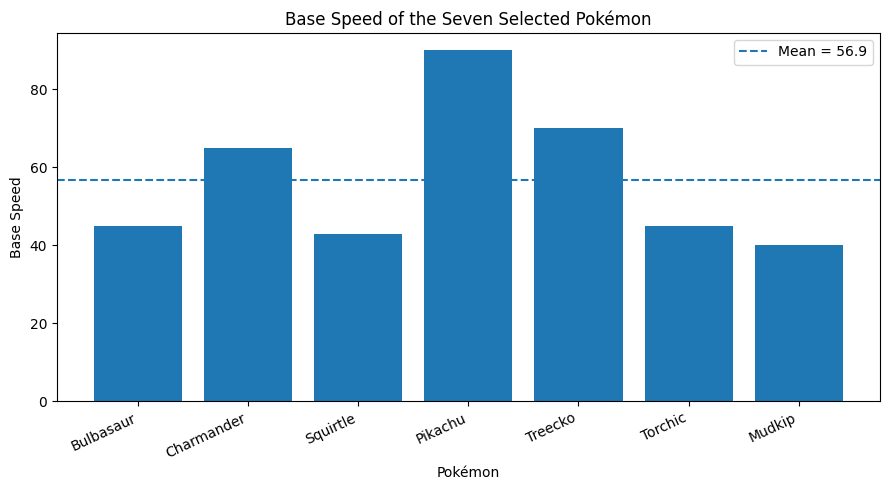

In [45]:
mean_speed = pokemon_df["speed"].mean()

plt.figure(figsize=(9, 5))
plt.bar(pokemon_df["name"], pokemon_df["speed"])
plt.axhline(mean_speed, linestyle="--", label=f"Mean = {mean_speed:.1f}")
plt.title("Base Speed of the Seven Selected Pokémon")
plt.xlabel("Pokémon")
plt.ylabel("Base Speed")
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Exploratory observation

The selected gen I pokemon have a mean Speed of  **60.75**, compared with  **51.67** for the selected gen III pokemon. This is a difference of about **9** points in this particular group. It does not prove that gen I pokemon are generally faster, but merely shows that the starters in gen I are generally fater.

## Reflection

#### What changes between live and archived data? Which check prevents the most misleading failure? How does caching support respectful use and reproducibility?

Live data comes directly from the API and may change when the API is updated. Archived data is saved in a JSON fixture, so it stays the same even if the API updates.


The check that prevents the most misleading failure is the validation. It makes sure the data contains the information we need, such as names and stats, before creating the DataFrame. Without this check, missing data would not pass.

Caching supports respectful use by reducing repeated requests to the API, which helps avoid unnecessary traffic. Also, it's easier to work with a fixture because the apis can and do update.
